In [ ]:
pip install sdv

In [2]:
dataset_path = "/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray"

In [3]:
import pandas as pd

In [4]:
import os
from collections import Counter

# Splits
splits = ['train', 'val', 'test']

# Store overall stats
total_counts = {}

for split in splits:

    
    split_path = os.path.join(dataset_path, split)
    classes = os.listdir(split_path)

    

In [5]:
    class_counts = {}
    
    for cls in classes:
        class_path = os.path.join(split_path, cls)
        
        # Count images
        num_images = len(os.listdir(class_path))
        class_counts[cls] = num_images
        
    
    total_counts[split] = class_counts

# Analyzing data

In [6]:
import os
from collections import Counter

# Splits
splits = ['train', 'val', 'test']

# Store overall stats
total_counts = {}

for split in splits:

    
    split_path = os.path.join(dataset_path, split)
    classes = os.listdir(split_path)

    
    class_counts = {}
    
    for cls in classes:
        class_path = os.path.join(split_path, cls)
        
        # Count images
        num_images = len(os.listdir(class_path))
        class_counts[cls] = num_images
        
    
    total_counts[split] = class_counts

# -----------------------------
# 📊 Total Summary
# -----------------------------
print("\n📊 Overall Summary")

for split, counts in total_counts.items():
    print(f"\n{split.upper()} distribution:")
    for cls, count in counts.items():
        print(f"{cls}: {count}")


📊 Overall Summary

TRAIN distribution:
PNEUMONIA: 3875
NORMAL: 1341

VAL distribution:
PNEUMONIA: 8
NORMAL: 8

TEST distribution:
PNEUMONIA: 390
NORMAL: 234


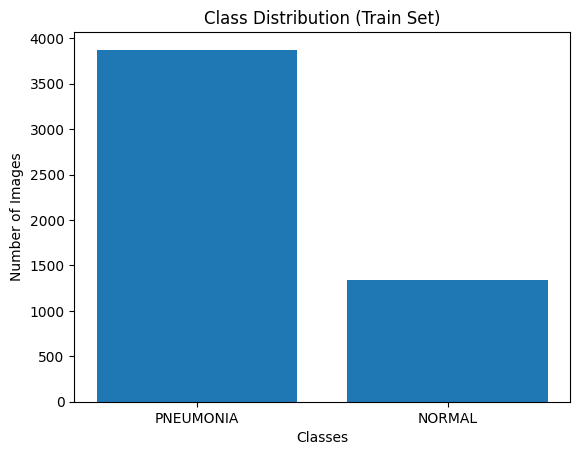

In [7]:
import matplotlib.pyplot as plt

# Example: visualize TRAIN set
train_counts = total_counts['train']

plt.bar(train_counts.keys(), train_counts.values())
plt.title("Class Distribution (Train Set)")
plt.xlabel("Classes")
plt.ylabel("Number of Images")
plt.show()

**We can see in train we have 3875 images for the disease but for the normal class we have 1341 images.**

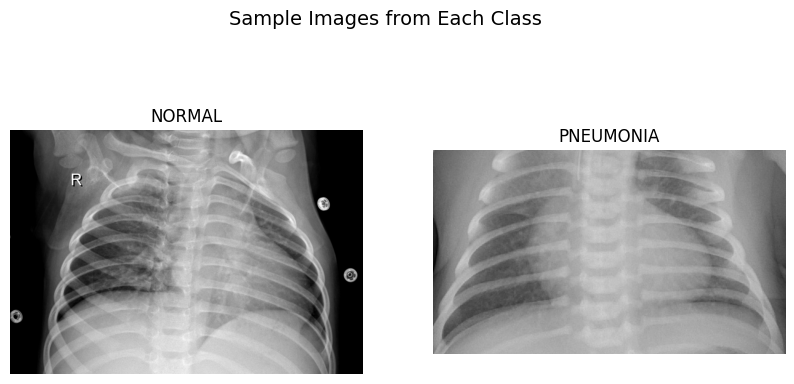

In [9]:
import os
import random
import matplotlib.pyplot as plt
from PIL import Image

# Path
dataset_path = "/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray/train"

classes = ["NORMAL", "PNEUMONIA"]

plt.figure(figsize=(10,5))

for i, cls in enumerate(classes):
    class_path = os.path.join(dataset_path, cls)
    
    # Pick a random image
    img_name = random.choice(os.listdir(class_path))
    img_path = os.path.join(class_path, img_name)
    
    img = Image.open(img_path)
    
    plt.subplot(1, 2, i+1)
    plt.imshow(img, cmap='gray')
    plt.title(cls)
    plt.axis('off')

plt.suptitle("Sample Images from Each Class", fontsize=14)
plt.show()

# Preprocessing the dataset for classifier:

In [10]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# Path
data_dir = "/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray"

# Transformations
transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.Grayscale(num_output_channels=3),  # convert to 3 channels
    transforms.ToTensor(),
    transforms.Normalize([0.5], [0.5])
])

# Datasets
train_data = datasets.ImageFolder(root=f"{data_dir}/train", transform=transform)
val_data   = datasets.ImageFolder(root=f"{data_dir}/val", transform=transform)
test_data  = datasets.ImageFolder(root=f"{data_dir}/test", transform=transform)

# Loaders
train_loader = DataLoader(train_data, batch_size=32, shuffle=True)
val_loader   = DataLoader(val_data, batch_size=32)
test_loader  = DataLoader(test_data, batch_size=32)

print("Classes:", train_data.classes)

Classes: ['NORMAL', 'PNEUMONIA']


# Modeling a Simple CNN:

In [11]:
import torch.nn as nn
import torch.nn.functional as F
import torch

class SimpleCNN(nn.Module):
    def __init__(self, num_classes=2):
        super(SimpleCNN, self).__init__()
        
        self.conv1 = nn.Conv2d(3, 16, 3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, 3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        
        self._to_linear = None  # will calculate dynamically
        self.fc1 = None
        self.fc2 = nn.Linear(128, num_classes)
        
    def forward(self, x):
        x = self.pool(nn.ReLU()(self.conv1(x)))
        x = self.pool(nn.ReLU()(self.conv2(x)))
        
        if self._to_linear is None:
            self._to_linear = x.numel() // x.shape[0]
            self.fc1 = nn.Linear(self._to_linear, 128).to(x.device)
        
        x = x.view(x.size(0), -1)  # flatten
        x = nn.ReLU()(self.fc1(x))
        x = self.fc2(x)
        return x

model = SimpleCNN()

In [12]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

epochs = 5

for epoch in range(epochs):
    model.train()
    running_loss = 0
    
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item()
    
    print(f"Epoch {epoch+1}, Loss: {running_loss/len(train_loader):.4f}")

Epoch 1, Loss: 0.4217
Epoch 2, Loss: 0.1581
Epoch 3, Loss: 0.1354
Epoch 4, Loss: 0.1187
Epoch 5, Loss: 0.1104


# Evaluation

In [13]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import numpy as np

model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        
        outputs = model(images)
        _, preds = torch.max(outputs, 1)
        
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

# Accuracy
print("Accuracy:", accuracy_score(all_labels, all_preds))

# Report
print("\nClassification Report:")
print(classification_report(all_labels, all_preds, target_names=train_data.classes))

Accuracy: 0.7980769230769231

Classification Report:
              precision    recall  f1-score   support

      NORMAL       0.94      0.50      0.65       234
   PNEUMONIA       0.76      0.98      0.86       390

    accuracy                           0.80       624
   macro avg       0.85      0.74      0.75       624
weighted avg       0.83      0.80      0.78       624



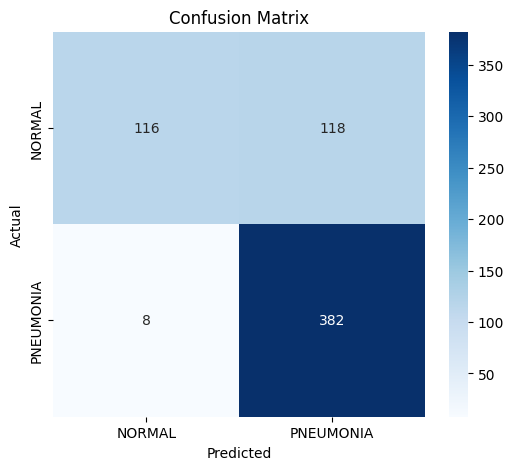

In [14]:
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=train_data.classes,
            yticklabels=train_data.classes)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

As seen, we have to fix the false positives in this case.

In [15]:
import torch

model.eval()

all_preds = []
all_labels = []
all_paths = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        
        outputs = model(images)
        _, preds = torch.max(outputs, 1)
        
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

        # 🔥 get file paths
        batch_paths = [test_data.samples[i][0] for i in range(len(all_paths), len(all_paths) + len(labels))]
        all_paths.extend(batch_paths)

In [17]:
# NORMAL (0) predicted as PNEUMONIA (1)
false_positives = df[(df["actual"] == 0) & (df["predicted"] == 1)]

print("False Positives:", len(false_positives))
false_positives.head()

False Positives: 118


,path,actual,predicted
1,/kaggle/input/datasets/paultimothymooney/chest...,0,1
3,/kaggle/input/datasets/paultimothymooney/chest...,0,1
7,/kaggle/input/datasets/paultimothymooney/chest...,0,1
14,/kaggle/input/datasets/paultimothymooney/chest...,0,1
16,/kaggle/input/datasets/paultimothymooney/chest...,0,1


Let's see some misclassified images by the model:

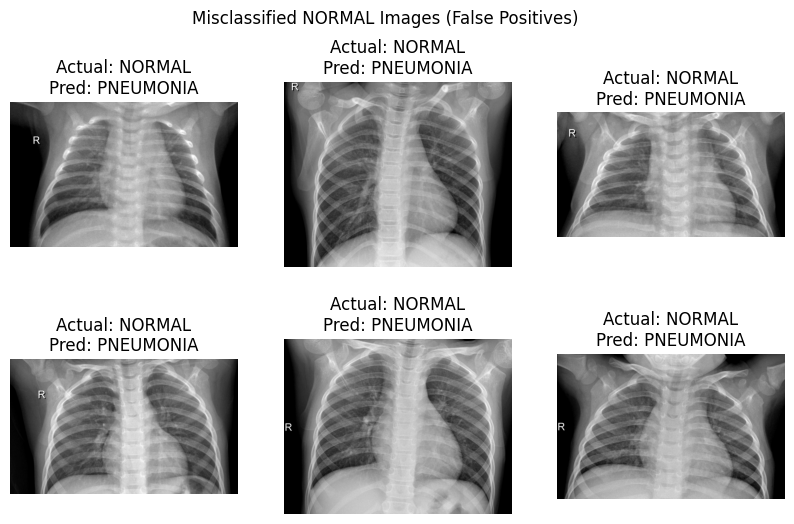

In [18]:
import matplotlib.pyplot as plt
from PIL import Image

sample_errors = false_positives.sample(6)

plt.figure(figsize=(10,6))

for i, row in enumerate(sample_errors.iterrows()):
    img_path = row[1]["path"]
    img = Image.open(img_path)
    
    plt.subplot(2, 3, i+1)
    plt.imshow(img, cmap='gray')
    plt.title("Actual: NORMAL\nPred: PNEUMONIA")
    plt.axis('off')

plt.suptitle("Misclassified NORMAL Images (False Positives)")
plt.show()

some of the images do look like pneumonia as seen above.

# Targetting the normal class and generating data using GAN:

In [19]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset
from torch.amp import GradScaler

# -----------------------------
# Hyperparameters
# -----------------------------
z_dim        = 100
img_size     = 64
img_channels = 3
batch_size   = 64
num_epochs   = 30
lr           = 0.0002
device       = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# -----------------------------
# Dataset — NORMAL class only
# -----------------------------

dataset_path = "/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray"

transform = transforms.Compose([
    transforms.Resize((img_size, img_size)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3)
])

full_train  = datasets.ImageFolder(root=f"{dataset_path}/train", transform=transform)
print("Classes:", full_train.classes)           # ['NORMAL', 'PNEUMONIA']

# Filter NORMAL only
normal_idx     = full_train.class_to_idx['NORMAL']
normal_indices = [i for i, (_, lbl) in enumerate(full_train.samples) if lbl == normal_idx]
normal_dataset = Subset(full_train, normal_indices)
print(f"Normal images available: {len(normal_dataset)}")

train_loader = DataLoader(
    normal_dataset,
    batch_size  = batch_size,
    shuffle     = True,
    num_workers = 4,
    pin_memory  = True,
    drop_last   = True
)

# -----------------------------
# Generator
# -----------------------------
class Generator(nn.Module):
    def __init__(self, z_dim=100, img_channels=3):
        super().__init__()
        self.net = nn.Sequential(
            nn.ConvTranspose2d(z_dim, 512, 4, 1, 0, bias=False),
            nn.BatchNorm2d(512),
            nn.ReLU(True),
            nn.ConvTranspose2d(512, 256, 4, 2, 1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(True),
            nn.ConvTranspose2d(256, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(True),
            nn.ConvTranspose2d(128, 64, 4, 2, 1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(True),
            nn.ConvTranspose2d(64, img_channels, 4, 2, 1, bias=False),
            nn.Tanh()
        )

    def forward(self, z):
        return self.net(z)

# -----------------------------
# Discriminator
# -----------------------------
class Discriminator(nn.Module):
    def __init__(self, img_channels=3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(img_channels, 64, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(64, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(128, 256, 4, 2, 1, bias=False),
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(256, 512, 4, 2, 1, bias=False),
            nn.BatchNorm2d(512),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(512, 1, 4, 1, 0, bias=False)
        )

    def forward(self, x):
        return self.net(x).view(x.size(0), -1)

# -----------------------------
# Initialize
# -----------------------------
G = Generator(z_dim=z_dim, img_channels=img_channels).to(device)
D = Discriminator(img_channels=img_channels).to(device)

def weights_init(m):
    classname = m.__class__.__name__
    if classname.find('Conv') != -1:
        nn.init.normal_(m.weight.data, 0.0, 0.02)
    elif classname.find('BatchNorm') != -1:
        nn.init.normal_(m.weight.data, 1.0, 0.02)
        nn.init.constant_(m.bias.data, 0)

G.apply(weights_init)
D.apply(weights_init)

optimizerD = optim.Adam(D.parameters(), lr=0.0001, betas=(0.5, 0.999))
optimizerG = optim.Adam(G.parameters(), lr=0.0002, betas=(0.5, 0.999))

criterion = nn.BCEWithLogitsLoss()
scaler_D  = GradScaler('cuda')
scaler_G  = GradScaler('cuda')

# -----------------------------
# Training Loop
# -----------------------------
for epoch in range(num_epochs):
    loss_D_total = 0.0
    loss_G_total = 0.0

    for real_imgs, _ in train_loader:
        real_imgs = real_imgs.to(device, non_blocking=True)
        b = real_imgs.size(0)

        real_labels = torch.ones(b, 1, device=device) * 0.9
        fake_labels = torch.zeros(b, 1, device=device)

        if torch.rand(1).item() < 0.05:
            real_labels, fake_labels = fake_labels, real_labels

        # ----- Train Discriminator -----
        optimizerD.zero_grad(set_to_none=True)
        with torch.amp.autocast('cuda'):
            outputs_real = D(real_imgs)
            z            = torch.randn(b, z_dim, 1, 1, device=device)
            fake_imgs    = G(z)
            outputs_fake = D(fake_imgs.detach())
            loss_D       = (criterion(outputs_real, real_labels) +
                            criterion(outputs_fake, fake_labels)) * 0.5

        scaler_D.scale(loss_D).backward()
        scaler_D.unscale_(optimizerD)
        torch.nn.utils.clip_grad_norm_(D.parameters(), 5)
        scaler_D.step(optimizerD)
        scaler_D.update()

        # ----- Train Generator -----
        optimizerG.zero_grad(set_to_none=True)
        with torch.amp.autocast('cuda'):
            z         = torch.randn(b, z_dim, 1, 1, device=device)
            fake_imgs = G(z)
            outputs   = D(fake_imgs)
            loss_G    = criterion(outputs, torch.ones_like(outputs))

        scaler_G.scale(loss_G).backward()
        scaler_G.unscale_(optimizerG)
        torch.nn.utils.clip_grad_norm_(G.parameters(), 5)
        scaler_G.step(optimizerG)
        scaler_G.update()

        loss_D_total += loss_D.item()
        loss_G_total += loss_G.item()

    avg_D = loss_D_total / len(train_loader)
    avg_G = loss_G_total / len(train_loader)

    if (epoch + 1) % 5 == 0:
        print(f"Epoch [{epoch+1}/{num_epochs}]  Avg Loss_D: {avg_D:.4f},  Avg Loss_G: {avg_G:.4f}")

# -----------------------------
# Save Generator
# -----------------------------
torch.save(G.state_dict(), "generator_normal_xray.pth")
print("Generator saved → generator_normal_xray.pth")

# -----------------------------
# Generate & save synthetic images
# -----------------------------
G.eval()
with torch.no_grad():
    z             = torch.randn(64, z_dim, 1, 1, device=device)
    synthetic     = G(z)
    synthetic     = (synthetic * 0.5) + 0.5        # denormalize to [0,1]
    print("Synthetic batch shape:", synthetic.shape)  # (64, 3, 64, 64)

Using device: cuda
Classes: ['NORMAL', 'PNEUMONIA']
Normal images available: 1341
Epoch [5/30]  Avg Loss_D: 0.2366,  Avg Loss_G: 8.3692
Epoch [10/30]  Avg Loss_D: 1.0240,  Avg Loss_G: 3.9551
Epoch [15/30]  Avg Loss_D: 0.7627,  Avg Loss_G: 2.0029
Epoch [20/30]  Avg Loss_D: 0.7781,  Avg Loss_G: 2.0815
Epoch [25/30]  Avg Loss_D: 0.7135,  Avg Loss_G: 1.3988
Epoch [30/30]  Avg Loss_D: 0.7377,  Avg Loss_G: 1.2743
Generator saved → generator_normal_xray.pth
Synthetic batch shape: torch.Size([64, 3, 64, 64])


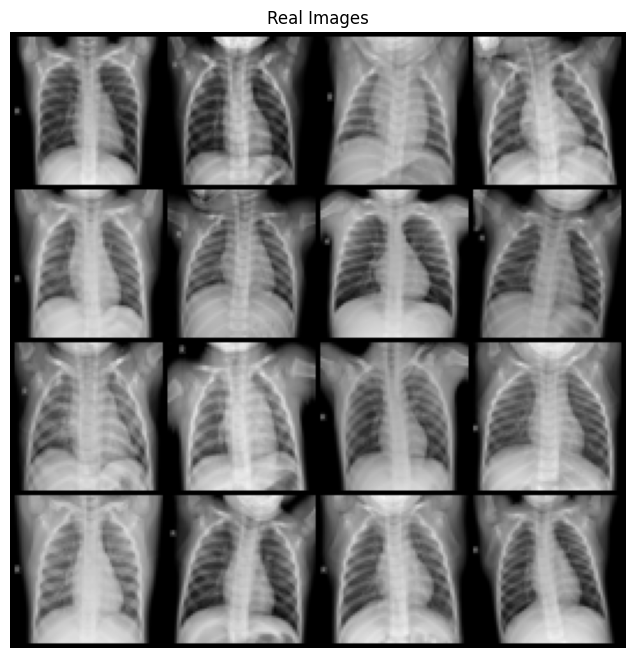

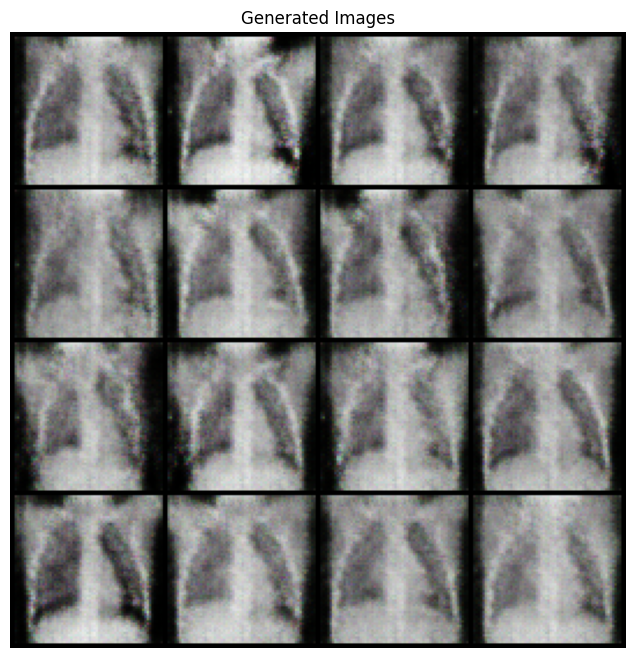

In [20]:
import matplotlib.pyplot as plt
import torchvision

# Get a batch of real images
real_imgs, _ = next(iter(train_loader))  # first batch from your DataLoader
real_imgs = real_imgs.to(device)

# Generate fake images
with torch.no_grad():
    z = torch.randn(real_imgs.size(0), z_dim, 1, 1, device=device)
    fake_imgs = G(z)

# Rescale images from [-1,1] to [0,1] for plotting
real_imgs = (real_imgs + 1) / 2
fake_imgs = (fake_imgs + 1) / 2

# Make grids
grid_real = torchvision.utils.make_grid(real_imgs[:16], nrow=4)
grid_fake = torchvision.utils.make_grid(fake_imgs[:16], nrow=4)

# Plot real images
plt.figure(figsize=(8,8))
plt.imshow(grid_real.permute(1,2,0).cpu())
plt.title("Real Images")
plt.axis('off')
plt.show()

# Plot generated images
plt.figure(figsize=(8,8))
plt.imshow(grid_fake.permute(1,2,0).cpu())
plt.title("Generated Images")
plt.axis('off')
plt.show()

In [21]:
num_synthetic = 1000
G.eval()
with torch.no_grad():
    z = torch.randn(num_synthetic, z_dim, 1, 1, device=device)
    synthetic_images = G(z)
    synthetic_images = (synthetic_images * 0.5) + 0.5  # denormalize [0,1]

# Assign labels (NORMAL = 0)
synthetic_labels = torch.zeros(num_synthetic, dtype=torch.long)

In [22]:
from torch.utils.data import TensorDataset, ConcatDataset, DataLoader
import torch

# ── Step 1: Drain the FULL train_loader into tensors ──────────────────────────
real_images_list = []
real_labels_list = []

model.eval()  # avoid dropout/batchnorm issues while collecting
with torch.no_grad():
    for imgs, lbls in train_loader:
        real_images_list.append(imgs.cpu())
        real_labels_list.append(lbls.cpu())

real_images = torch.cat(real_images_list, dim=0)
real_labels = torch.cat(real_labels_list, dim=0)

print(f"✅ Real images collected:      {real_images.shape}")      # e.g. (5216, 3, 224, 224)
print(f"✅ Synthetic images to add:    {synthetic_images.shape}") # e.g. (N,    3, 224, 224)
print(f"   Real label distribution:    NORMAL={( real_labels==0).sum()}  PNEUMONIA={(real_labels==1).sum()}")

# ── Step 2: Combine real + synthetic into ONE dataset ─────────────────────────
augmented_images = torch.cat([real_images, synthetic_images.cpu()], dim=0)
augmented_labels = torch.cat([real_labels, synthetic_labels.cpu()], dim=0)

augmented_dataset = TensorDataset(augmented_images, augmented_labels)
augmented_loader  = DataLoader(augmented_dataset, batch_size=64, shuffle=True, num_workers=0)

print(f"\n✅ Augmented dataset size: {len(augmented_dataset)}")
print(f"   NORMAL={(augmented_labels==0).sum()}  PNEUMONIA={(augmented_labels==1).sum()}")

# ── Step 3: Retrain on the FULL augmented dataset ─────────────────────────────
device    = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
model.train()

num_epochs_cls = 5
criterion  = nn.CrossEntropyLoss()
optimizer  = torch.optim.Adam(model.parameters(), lr=0.001)

for epoch in range(num_epochs_cls):
    model.train()
    running_loss   = 0.0
    correct, total = 0, 0

    for imgs, lbls in augmented_loader:
        imgs, lbls = imgs.to(device), lbls.to(device)

        optimizer.zero_grad()
        outputs = model(imgs)
        loss    = criterion(outputs, lbls)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        preds         = outputs.argmax(dim=1)
        correct      += (preds == lbls).sum().item()
        total        += lbls.size(0)

    acc = 100 * correct / total
    print(f"Epoch [{epoch+1}/{num_epochs_cls}]  "
          f"Loss: {running_loss/len(augmented_loader):.4f}  "
          f"Train Acc: {acc:.2f}%")

✅ Real images collected:      torch.Size([1280, 3, 64, 64])
✅ Synthetic images to add:    torch.Size([1000, 3, 64, 64])
   Real label distribution:    NORMAL=1280  PNEUMONIA=0

✅ Augmented dataset size: 2280
   NORMAL=2280  PNEUMONIA=0
Epoch [1/5]  Loss: 0.0818  Train Acc: 98.46%
Epoch [2/5]  Loss: 0.0000  Train Acc: 100.00%
Epoch [3/5]  Loss: 0.0000  Train Acc: 100.00%
Epoch [4/5]  Loss: 0.0000  Train Acc: 100.00%
Epoch [5/5]  Loss: 0.0000  Train Acc: 100.00%


In [23]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

num_epochs_cls = 5

criterion = nn.CrossEntropyLoss()  # define once outside loop
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

for epoch in range(num_epochs_cls):
    model.train()
    running_loss = 0
    
    for imgs, lbls in augmented_loader:
        imgs, lbls = imgs.to(device), lbls.to(device)  # ensure both on same device
        
        optimizer.zero_grad()
        outputs = model(imgs)        # use 'imgs'
        loss = criterion(outputs, lbls)  # use 'lbls'
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item()
    
    print(f"Epoch {epoch+1}, Loss: {running_loss/len(augmented_loader):.4f}")

Epoch 1, Loss: 0.0000
Epoch 2, Loss: 0.0000
Epoch 3, Loss: 0.0000
Epoch 4, Loss: 0.0000
Epoch 5, Loss: 0.0000


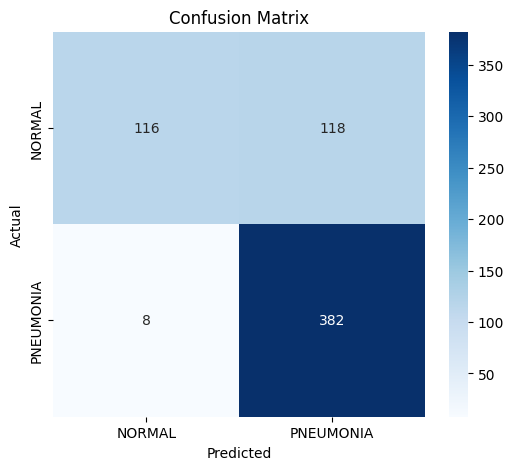


Classification Report:
              precision    recall  f1-score   support

      NORMAL       0.94      0.50      0.65       234
   PNEUMONIA       0.76      0.98      0.86       390

    accuracy                           0.80       624
   macro avg       0.85      0.74      0.75       624
weighted avg       0.83      0.80      0.78       624



In [24]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

classes = ['NORMAL', 'PNEUMONIA']

# Compute confusion matrix with fixed labels
cm = confusion_matrix(all_labels, all_preds, labels=[0, 1])

# Plot confusion matrix
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

# Classification report with labels specified
print("\nClassification Report:")
print(classification_report(all_labels, all_preds, labels=[0,1], target_names=classes, zero_division=0))

In [25]:
from collections import Counter

all_labels = []
for _, lbls in augmented_loader:
    all_labels.extend(lbls.numpy())
print(Counter(all_labels))

Counter({np.int64(0): 2280})


Class weights → NORMAL: 1.328  PNEUMONIA: 0.802
Epoch [1/5]  Loss: 0.2333  Train Acc: 96.56%
Epoch [2/5]  Loss: 0.2036  Train Acc: 96.93%
Epoch [3/5]  Loss: 0.1769  Train Acc: 97.31%
Epoch [4/5]  Loss: 0.1646  Train Acc: 97.43%
Epoch [5/5]  Loss: 0.1466  Train Acc: 97.22%


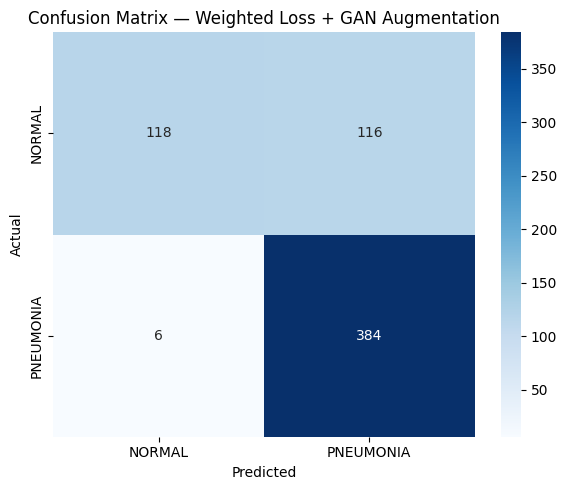

              precision    recall  f1-score   support

      NORMAL       0.95      0.50      0.66       234
   PNEUMONIA       0.77      0.98      0.86       390

    accuracy                           0.80       624
   macro avg       0.86      0.74      0.76       624
weighted avg       0.84      0.80      0.79       624

TP: 384  FN: 6  TN: 118  FP: 116
Sensitivity: 98.46%
Specificity: 50.43%


In [34]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, ConcatDataset, TensorDataset
from collections import Counter
import torch
import torch.nn as nn

# ── Same setup as before ──────────────────────────────────────────────────────
train_transforms = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])

full_train_dataset = datasets.ImageFolder(
    root=os.path.join(dataset_path, "train"),
    transform=train_transforms
)

counts     = Counter(full_train_dataset.targets)
normal_idx = full_train_dataset.class_to_idx['NORMAL']  # 0

synthetic_labels  = torch.full((len(synthetic_images),), normal_idx, dtype=torch.long)
synthetic_dataset = TensorDataset(synthetic_images.cpu(), synthetic_labels)

augmented_dataset = ConcatDataset([full_train_dataset, synthetic_dataset])

def custom_collate(batch):
    imgs   = torch.stack([item[0] for item in batch])
    labels = torch.tensor([item[1] for item in batch], dtype=torch.long)
    return imgs, labels

augmented_loader = DataLoader(
    augmented_dataset,
    batch_size=64,
    shuffle=True,
    num_workers=0,
    collate_fn=custom_collate
)

# ── Weighted loss — the actual fix ────────────────────────────────────────────
n_normal    = counts[normal_idx] + len(synthetic_images)  # 2341
n_pneumonia = counts[1 - normal_idx]                      # 3875
total       = n_normal + n_pneumonia                      # 6216

weight_normal    = total / (2 * n_normal)      # ~1.33  (penalise missing NORMAL more)
weight_pneumonia = total / (2 * n_pneumonia)   # ~0.80

class_weights = torch.tensor([weight_normal, weight_pneumonia])

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights.to(device))  # ← weighted
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

print(f"Class weights → NORMAL: {weight_normal:.3f}  PNEUMONIA: {weight_pneumonia:.3f}")

# ── Retrain ───────────────────────────────────────────────────────────────────
for epoch in range(5):
    model.train()
    running_loss = 0.0
    correct, total_samples = 0, 0

    for imgs, lbls in augmented_loader:
        imgs, lbls = imgs.to(device), lbls.to(device)

        optimizer.zero_grad()
        outputs = model(imgs)
        loss    = criterion(outputs, lbls)
        loss.backward()
        optimizer.step()

        running_loss    += loss.item()
        correct         += (outputs.argmax(1) == lbls).sum().item()
        total_samples   += lbls.size(0)

    print(f"Epoch [{epoch+1}/5]  Loss: {running_loss/len(augmented_loader):.4f}  "
          f"Train Acc: {correct/total_samples*100:.2f}%")

# ── Confusion matrix right after ─────────────────────────────────────────────
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

test_dataset = datasets.ImageFolder(
    root=os.path.join(dataset_path, "test"),
    transform=train_transforms
)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False, num_workers=0)

model.eval()
all_preds, all_labels = [], []

with torch.no_grad():
    for imgs, lbls in test_loader:
        imgs = imgs.to(device)
        all_preds.extend(model(imgs).argmax(1).cpu().tolist())
        all_labels.extend(lbls.tolist())

cm = confusion_matrix(all_labels, all_preds)
TN, FP, FN, TP = cm.ravel()

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=test_dataset.classes,
            yticklabels=test_dataset.classes)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix — Weighted Loss + GAN Augmentation')
plt.tight_layout()
plt.show()

print(classification_report(all_labels, all_preds, target_names=test_dataset.classes))
print(f"TP: {TP}  FN: {FN}  TN: {TN}  FP: {FP}")
print(f"Sensitivity: {TP/(TP+FN)*100:.2f}%")
print(f"Specificity: {TN/(TN+FP)*100:.2f}%")

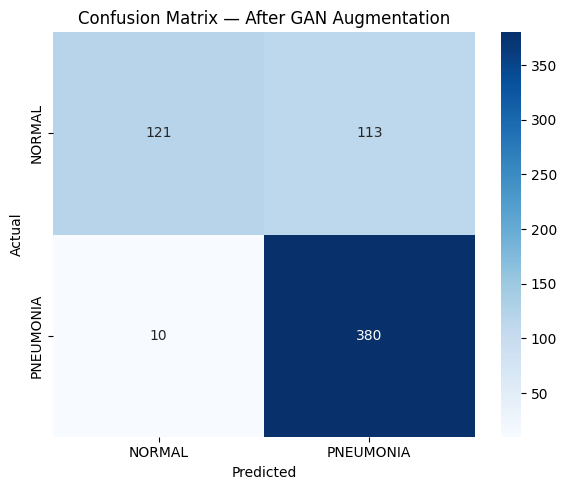

              precision    recall  f1-score   support

      NORMAL       0.92      0.52      0.66       234
   PNEUMONIA       0.77      0.97      0.86       390

    accuracy                           0.80       624
   macro avg       0.85      0.75      0.76       624
weighted avg       0.83      0.80      0.79       624

TP (Pneumonia correctly detected): 380
FN (Pneumonia missed):             10
TN (Normal correctly detected):    121
FP (Normal misclassified):         113
Sensitivity (Recall):              97.44%
Specificity:                       51.71%


In [33]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# ── Evaluate on test set ──────────────────────────────────────────────────────
test_transforms = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])

test_dataset = datasets.ImageFolder(
    root=os.path.join(dataset_path, "test"),
    transform=test_transforms
)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False, num_workers=0)

model.eval()
all_preds, all_labels = [], []

with torch.no_grad():
    for imgs, lbls in test_loader:
        imgs = imgs.to(device)
        preds = model(imgs).argmax(dim=1).cpu()
        all_preds.extend(preds.tolist())
        all_labels.extend(lbls.tolist())

# ── Confusion Matrix ──────────────────────────────────────────────────────────
cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=test_dataset.classes,
            yticklabels=test_dataset.classes)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix — After GAN Augmentation')
plt.tight_layout()
plt.show()

# ── Classification Report ─────────────────────────────────────────────────────
print(classification_report(all_labels, all_preds, target_names=test_dataset.classes))

# ── Key metrics ───────────────────────────────────────────────────────────────
TN, FP, FN, TP = cm.ravel()
print(f"TP (Pneumonia correctly detected): {TP}")
print(f"FN (Pneumonia missed):             {FN}")
print(f"TN (Normal correctly detected):    {TN}")
print(f"FP (Normal misclassified):         {FP}")
print(f"Sensitivity (Recall):              {TP/(TP+FN)*100:.2f}%")
print(f"Specificity:                       {TN/(TN+FP)*100:.2f}%")

# Checking the quality of augmentation

Real NORMAL shape:  (1341, 3, 64, 64)
Synthetic shape:    (1000, 3, 64, 64)

📊 Pixel-Level Statistics
Metric             Real  Synthetic       Diff
---------------------------------------------
mean            -0.0401     0.5005     0.5406
std              0.4821     0.2250     0.2572
min             -1.0000     0.0000     1.0000
max              1.0000     0.9836     0.0164
median           0.0353     0.5406     0.5053


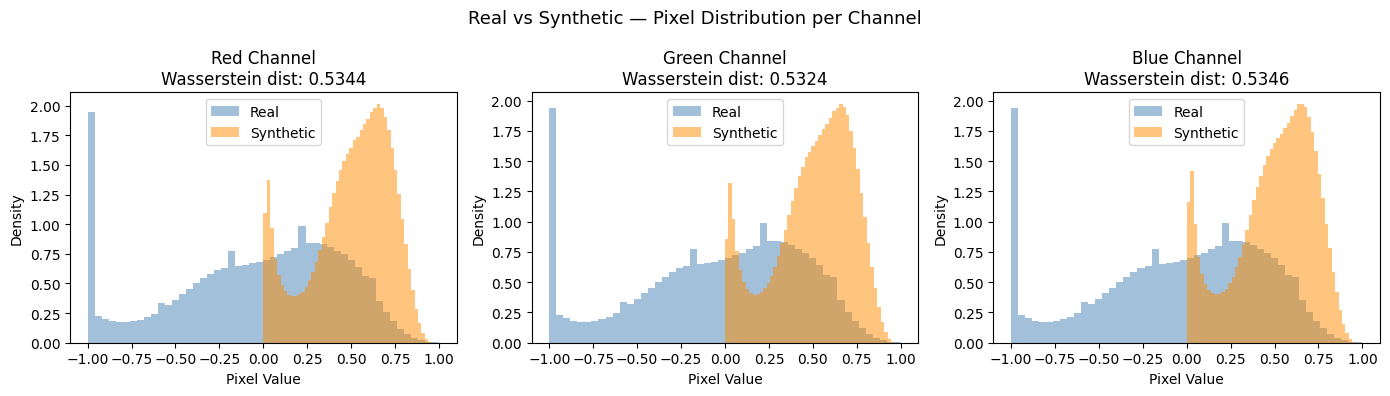


📊 Kolmogorov-Smirnov Test (per channel)
Channel       KS Stat      p-value   Similar?
---------------------------------------------
Red            0.5446       0.0000       ❌ No
Green          0.5306       0.0000       ❌ No
Blue           0.5352       0.0000       ❌ No

📊 SSIM (mean image structural similarity): 0.7583
   (1.0 = identical, >0.7 = good, <0.5 = poor)


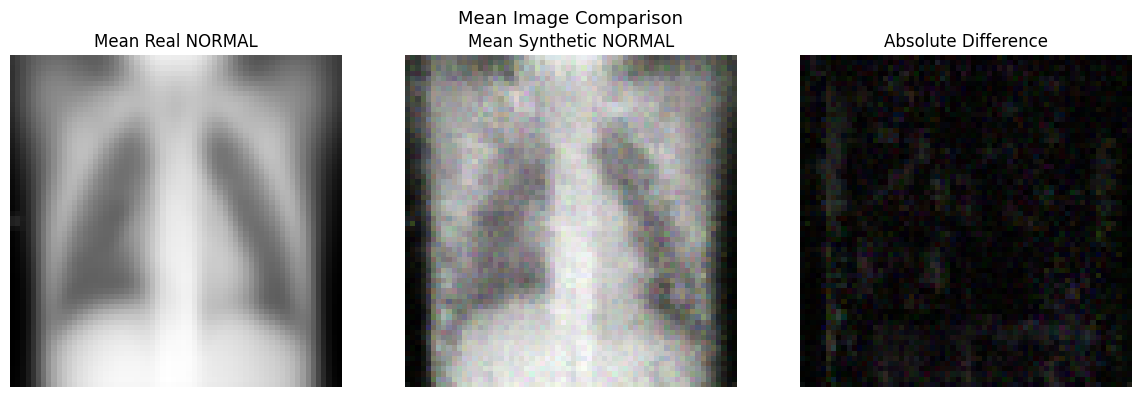

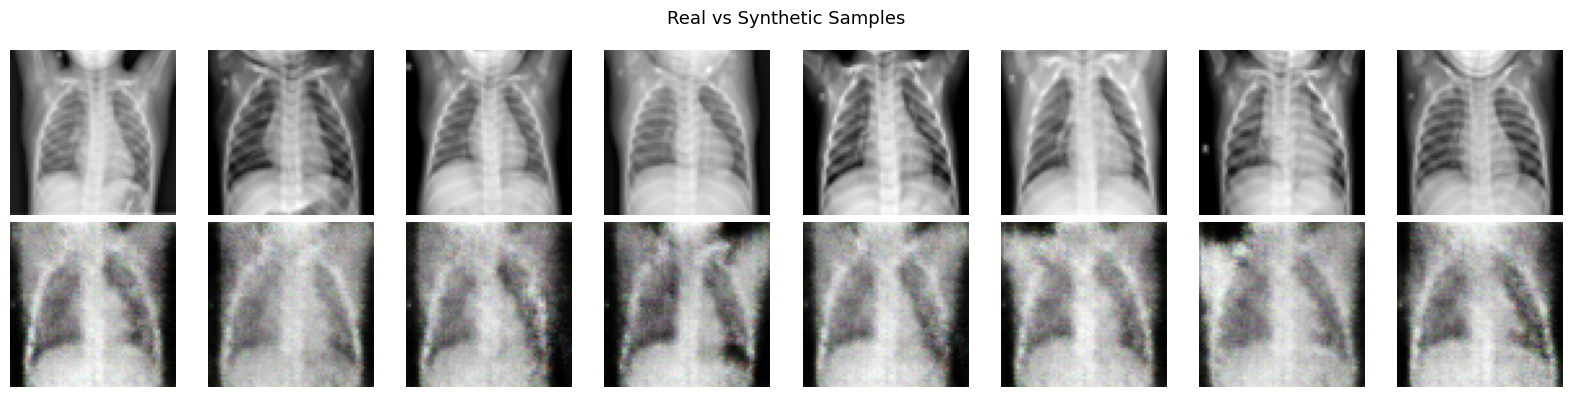


📋 Synthetic Data Quality Summary
  Pixel mean diff:       0.5406
  Pixel std diff:        0.2572
  SSIM score:            0.7583
  Wasserstein (R chan):  (see chart)
  ✅ Synthetic images are structurally close to real


In [35]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import wasserstein_distance
from skimage.metrics import structural_similarity as ssim
import torch

# ── Step 1: Extract real NORMAL images as numpy ───────────────────────────────
real_normal_imgs = []

for imgs, lbls in DataLoader(full_train_dataset, batch_size=64, shuffle=False,
                              num_workers=0):
    mask = lbls == normal_idx
    if mask.any():
        real_normal_imgs.append(imgs[mask])

real_normal_imgs = torch.cat(real_normal_imgs).cpu().numpy()  # (1341, 3, 64, 64)
synthetic_np     = synthetic_images.cpu().numpy()             # (1000, 3, 64, 64)

print(f"Real NORMAL shape:  {real_normal_imgs.shape}")
print(f"Synthetic shape:    {synthetic_np.shape}")

# ── Step 2: Pixel-level statistics ───────────────────────────────────────────
def get_stats(imgs):
    return {
        "mean":    imgs.mean(),
        "std":     imgs.std(),
        "min":     imgs.min(),
        "max":     imgs.max(),
        "median":  np.median(imgs)
    }

real_stats = get_stats(real_normal_imgs)
syn_stats  = get_stats(synthetic_np)

print("\n📊 Pixel-Level Statistics")
print(f"{'Metric':<12} {'Real':>10} {'Synthetic':>10} {'Diff':>10}")
print("-" * 45)
for k in real_stats:
    diff = abs(real_stats[k] - syn_stats[k])
    print(f"{k:<12} {real_stats[k]:>10.4f} {syn_stats[k]:>10.4f} {diff:>10.4f}")

# ── Step 3: Per-channel mean & std comparison ─────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
channel_names = ['Red', 'Green', 'Blue']

for c in range(3):
    real_flat = real_normal_imgs[:, c, :, :].flatten()
    syn_flat  = synthetic_np[:, c, :, :].flatten()

    # Wasserstein distance (lower = more similar distributions)
    wd = wasserstein_distance(
        np.random.choice(real_flat, 5000),   # sample for speed
        np.random.choice(syn_flat,  5000)
    )

    axes[c].hist(real_flat, bins=50, alpha=0.5, label='Real',      color='steelblue',  density=True)
    axes[c].hist(syn_flat,  bins=50, alpha=0.5, label='Synthetic', color='darkorange', density=True)
    axes[c].set_title(f'{channel_names[c]} Channel\nWasserstein dist: {wd:.4f}')
    axes[c].legend()
    axes[c].set_xlabel('Pixel Value')
    axes[c].set_ylabel('Density')

plt.suptitle('Real vs Synthetic — Pixel Distribution per Channel', fontsize=13)
plt.tight_layout()
plt.show()

# ── Step 4: KS Test (are distributions statistically similar?) ────────────────
print("\n📊 Kolmogorov-Smirnov Test (per channel)")
print(f"{'Channel':<10} {'KS Stat':>10} {'p-value':>12} {'Similar?':>10}")
print("-" * 45)

for c in range(3):
    real_flat = real_normal_imgs[:, c, :, :].flatten()
    syn_flat  = synthetic_np[:, c, :, :].flatten()
    ks_stat, p_val = stats.ks_2samp(
        np.random.choice(real_flat, 5000),
        np.random.choice(syn_flat,  5000)
    )
    similar = "✅ Yes" if p_val > 0.05 else "❌ No"
    print(f"{channel_names[c]:<10} {ks_stat:>10.4f} {p_val:>12.4f} {similar:>10}")

# ── Step 5: SSIM — structural similarity ─────────────────────────────────────
# Compare mean real image vs mean synthetic image
mean_real = real_normal_imgs.mean(axis=0).transpose(1, 2, 0)  # (64,64,3)
mean_syn  = synthetic_np.mean(axis=0).transpose(1, 2, 0)

# Normalize to [0,1] for SSIM
def norm01(x):
    return (x - x.min()) / (x.max() - x.min() + 1e-8)

mean_real_n = norm01(mean_real)
mean_syn_n  = norm01(mean_syn)

ssim_score = ssim(mean_real_n, mean_syn_n, channel_axis=2, data_range=1.0)
print(f"\n📊 SSIM (mean image structural similarity): {ssim_score:.4f}")
print(f"   (1.0 = identical, >0.7 = good, <0.5 = poor)")

# ── Step 6: Visual comparison — mean images ───────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(norm01(mean_real_n))
axes[0].set_title('Mean Real NORMAL')
axes[0].axis('off')

axes[1].imshow(norm01(mean_syn_n))
axes[1].set_title('Mean Synthetic NORMAL')
axes[1].axis('off')

diff = np.abs(mean_real_n - mean_syn_n)
axes[2].imshow(diff, cmap='hot')
axes[2].set_title('Absolute Difference')
axes[2].axis('off')

plt.suptitle('Mean Image Comparison', fontsize=13)
plt.tight_layout()
plt.show()

# ── Step 7: Sample grid — real vs synthetic side by side ──────────────────────
fig, axes = plt.subplots(2, 8, figsize=(16, 4))

for i in range(8):
    img_r = norm01(real_normal_imgs[i].transpose(1, 2, 0))
    img_s = norm01(synthetic_np[i].transpose(1, 2, 0))
    axes[0, i].imshow(img_r)
    axes[0, i].axis('off')
    axes[1, i].imshow(img_s)
    axes[1, i].axis('off')

axes[0, 0].set_ylabel('Real',      fontsize=12)
axes[1, 0].set_ylabel('Synthetic', fontsize=12)
plt.suptitle('Real vs Synthetic Samples', fontsize=13)
plt.tight_layout()
plt.show()

# ── Step 8: Final quality summary ────────────────────────────────────────────
print("\n📋 Synthetic Data Quality Summary")
print("=" * 45)
print(f"  Pixel mean diff:       {abs(real_stats['mean'] - syn_stats['mean']):.4f}")
print(f"  Pixel std diff:        {abs(real_stats['std']  - syn_stats['std']):.4f}")
print(f"  SSIM score:            {ssim_score:.4f}")
print(f"  Wasserstein (R chan):  (see chart)")
print("=" * 45)
if ssim_score > 0.7:
    print("  ✅ Synthetic images are structurally close to real")
elif ssim_score > 0.5:
    print("  ⚠️  Moderate similarity — GAN may need more training")
else:
    print("  ❌ Low similarity — GAN quality is poor")